# Exploración y diagnóstico del Dry Bean Dataset

**Actividad de Evaluación 1 - Unidad II**  
**Estudiante:** Kevin Hernandez Trejo · **Matrícula:** 23300950 · **Grupo:** 10IDGS-G1  
**Proyecto:** Clasificación automática y análisis morfológico de variedades de frijol  
**Dataset:** Dry Bean Dataset · **Fuente:** UCI Machine Learning Repository  

## Propósito

Explorar el archivo original sin modificarlo, documentar su estructura y sus variables, diagnosticar su calidad, describir estadísticamente las mediciones morfológicas y proponer variables para regresión, clasificación y agrupamiento.

> Este notebook solo lee `data/raw/`. No elimina duplicados, no imputa valores y no sobrescribe el dataset original.

## 1. Preparación del entorno y localización del archivo

Se importan Pandas para la exploración y Matplotlib/Seaborn para las gráficas. La búsqueda del directorio raíz permite ejecutar el notebook desde la carpeta del repositorio o desde `notebooks/`.

In [1]:
from pathlib import Path
import hashlib
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / "data").exists() else cwd.parent
DATA_PATH = ROOT / "data" / "raw" / "dry_bean_dataset" / "DryBeanDataset" / "Dry_Bean_Dataset.xlsx"
assert DATA_PATH.exists(), f"No se encontró el dataset: {DATA_PATH}"

raw_hash_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Archivo: {DATA_PATH.relative_to(ROOT)}")
print(f"SHA-256 inicial: {raw_hash_before}")

Archivo: data\raw\dry_bean_dataset\DryBeanDataset\Dry_Bean_Dataset.xlsx
SHA-256 inicial: a9efa69741c6c5d95167c962a13da23a456f7e940402a5add12639790e01f714


**Interpretación.** La ruta apunta al Excel original dentro de `data/raw/`. La huella SHA-256 permitirá comprobar al final que el archivo permaneció sin modificaciones.

## 2. Identificación y carga del dataset

El Dry Bean Dataset contiene mediciones obtenidas al segmentar imágenes de granos con un sistema de visión por computadora. Cada fila representa un grano; las 16 variables predictoras describen tamaño, proporción y forma, mientras `Class` identifica una de siete variedades.

- **Formato utilizado:** XLSX.
- **Fuente:** UCI Machine Learning Repository, DOI 10.24432/C50S4B.
- **Tipo de fuente:** datos biométricos/morfológicos generados por máquina a partir de imágenes.
- **Estructura:** datos estructurados en una tabla de filas y columnas.

In [2]:
df = pd.read_excel(DATA_PATH)
print("Dataset cargado correctamente.")

Dataset cargado correctamente.


**Interpretación.** `pd.read_excel()` carga el libro en un `DataFrame` sin alterar el archivo. Todo el diagnóstico posterior se realiza en memoria.

## 3. Exploración inicial con Pandas

### 3.1 Primeras filas: `df.head()`

In [3]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291000,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018000,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110000,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884000,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134000,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


**Interpretación.** Las primeras cinco filas confirman que las mediciones morfológicas son numéricas y que `Class` es la etiqueta categórica. Cada renglón representa un grano distinto.

### 3.2 Dimensiones: `df.shape`

In [4]:
df.shape

(13611, 17)

**Interpretación.** El conjunto contiene **13,611 registros y 17 columnas**: 16 características morfológicas y una variable de clase.

### 3.3 Nombres de columnas: `df.columns`

In [5]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

**Interpretación.** Los nombres conservan la forma original de UCI. Se detectan dos detalles de nomenclatura para una etapa posterior: `AspectRation` parece un error tipográfico de *AspectRatio* y `roundness` no sigue la capitalización de las demás variables. En esta actividad no se renombran.

### 3.4 Resumen estructural: `df.info()`

In [6]:
buffer = io.StringIO()
df.info(buf=buffer)
print(buffer.getvalue())

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

**Interpretación.** Las 17 columnas tienen 13,611 valores no nulos. `Area` y `ConvexArea` son enteras; 14 mediciones son `float64`; `Class` es texto. La estructura es adecuada para análisis tabular.

### 3.5 Tipos de datos: `df.dtypes`

In [7]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

**Interpretación.** Los tipos son coherentes con el significado de las variables. No se detectan números almacenados como texto ni fechas que requieran conversión.

### 3.6 Estadística descriptiva general: `df.describe()`

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,"13,611.000000","53,048.284549","29,324.095717","20,420.000000","36,328.000000","44,652.000000","61,332.000000","254,616.000000"
Perimeter,"13,611.000000",855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,"1,985.370000"
MajorAxisLength,"13,611.000000",320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,"13,611.000000",202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,"13,611.000000",1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,"13,611.000000",0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,"13,611.000000","53,768.200206","29,774.915817","20,684.000000","36,714.500000","45,178.000000","62,294.000000","263,261.000000"
EquivDiameter,"13,611.000000",253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,"13,611.000000",0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,"13,611.000000",0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


**Interpretación.** Las escalas varían ampliamente: `Area` se mide en decenas de miles de píxeles, mientras los factores de forma usan valores pequeños o proporciones entre 0 y 1. Para clustering y algoritmos sensibles a distancia será necesario estandarizar más adelante, pero aquí no se transforma nada.

## 4. Diccionario de datos y clasificación de variables

Las descripciones se basan en la documentación oficial del dataset. Las variables numéricas son cuantitativas; `Area` y `ConvexArea` son discretas por ser conteos de píxeles, las demás mediciones se tratan como continuas y `Class` es cualitativa nominal.

In [9]:
descripciones = {
    "Area": ("Número de píxeles dentro del contorno del grano", "Cuantitativa", "Discreta", "px²", "Objetivo de regresión y descriptor de tamaño"),
    "Perimeter": ("Longitud del borde del grano", "Cuantitativa", "Continua", "px", "Tamaño y forma; predictor"),
    "MajorAxisLength": ("Longitud del eje mayor de la elipse equivalente", "Cuantitativa", "Continua", "px", "Alargamiento y tamaño"),
    "MinorAxisLength": ("Longitud del eje menor perpendicular al eje mayor", "Cuantitativa", "Continua", "px", "Ancho y tamaño"),
    "AspectRation": ("Razón entre eje mayor y eje menor", "Cuantitativa", "Continua", "Adimensional", "Distinguir granos redondos y alargados"),
    "Eccentricity": ("Excentricidad de la elipse equivalente", "Cuantitativa", "Continua", "0 a <1", "Descriptor de elongación"),
    "ConvexArea": ("Píxeles del menor polígono convexo que contiene al grano", "Cuantitativa", "Discreta", "px²", "Tamaño de la envolvente convexa"),
    "EquivDiameter": ("Diámetro del círculo con la misma área", "Cuantitativa", "Continua", "px", "Tamaño equivalente; derivado de Area"),
    "Extent": ("Proporción del área respecto a la caja delimitadora", "Cuantitativa", "Continua", "0 a 1", "Ocupación espacial"),
    "Solidity": ("Proporción entre Area y ConvexArea", "Cuantitativa", "Continua", "0 a 1", "Regularidad y convexidad"),
    "roundness": ("Índice de redondez 4πArea/Perimeter²", "Cuantitativa", "Continua", "0 a 1", "Separación por circularidad"),
    "Compactness": ("Relación EquivDiameter/MajorAxisLength", "Cuantitativa", "Continua", "0 a 1", "Compacidad del grano"),
    "ShapeFactor1": ("Primer factor morfológico", "Cuantitativa", "Continua", "Adimensional", "Patrón de forma para modelado"),
    "ShapeFactor2": ("Segundo factor morfológico", "Cuantitativa", "Continua", "Adimensional", "Patrón de forma para modelado"),
    "ShapeFactor3": ("Tercer factor morfológico", "Cuantitativa", "Continua", "0 a 1", "Patrón de forma para modelado"),
    "ShapeFactor4": ("Cuarto factor morfológico", "Cuantitativa", "Continua", "0 a 1", "Patrón de forma para modelado"),
    "Class": ("Variedad registrada del frijol", "Cualitativa", "Nominal", "Categoría", "Objetivo de clasificación; contraste de clusters"),
}

diccionario = pd.DataFrame([
    {
        "Variable": c,
        "Descripción": descripciones[c][0],
        "Tipo Python": str(df[c].dtype),
        "Tipo de variable": descripciones[c][1],
        "Clasificación": descripciones[c][2],
        "Unidad": descripciones[c][3],
        "Posible utilidad": descripciones[c][4],
    }
    for c in df.columns
])
display(diccionario)

,Variable,Descripción,Tipo Python,Tipo de variable,Clasificación,Unidad,Posible utilidad
0,Area,Número de píxeles dentro del contorno del grano,int64,Cuantitativa,Discreta,px²,Objetivo de regresión y descriptor de tamaño
1,Perimeter,Longitud del borde del grano,float64,Cuantitativa,Continua,px,Tamaño y forma; predictor
2,MajorAxisLength,Longitud del eje mayor de la elipse equivalente,float64,Cuantitativa,Continua,px,Alargamiento y tamaño
3,MinorAxisLength,Longitud del eje menor perpendicular al eje mayor,float64,Cuantitativa,Continua,px,Ancho y tamaño
4,AspectRation,Razón entre eje mayor y eje menor,float64,Cuantitativa,Continua,Adimensional,Distinguir granos redondos y alargados
5,Eccentricity,Excentricidad de la elipse equivalente,float64,Cuantitativa,Continua,0 a <1,Descriptor de elongación
6,ConvexArea,Píxeles del menor polígono convexo que contien...,int64,Cuantitativa,Discreta,px²,Tamaño de la envolvente convexa
7,EquivDiameter,Diámetro del círculo con la misma área,float64,Cuantitativa,Continua,px,Tamaño equivalente; derivado de Area
8,Extent,Proporción del área respecto a la caja delimit...,float64,Cuantitativa,Continua,0 a 1,Ocupación espacial
9,Solidity,Proporción entre Area y ConvexArea,float64,Cuantitativa,Continua,0 a 1,Regularidad y convexidad


**Interpretación.** El diccionario documenta las 17 columnas. La mayoría son mediciones continuas de forma; `Class` es la única variable cualitativa. Algunas variables son matemáticamente derivadas de otras, aspecto importante para prevenir fuga de información en regresión.

## 5. Diagnóstico de calidad

### 5.1 Valores faltantes: `df.isnull().sum()`

In [10]:
faltantes = pd.DataFrame({
    "Faltantes": df.isnull().sum(),
    "Porcentaje": df.isnull().mean().mul(100)
})
display(faltantes)
print(f"Total de valores faltantes: {int(faltantes['Faltantes'].sum())}")

,Faltantes,Porcentaje
Area,0,0.000000
Perimeter,0,0.000000
MajorAxisLength,0,0.000000
MinorAxisLength,0,0.000000
AspectRation,0,0.000000
Eccentricity,0,0.000000
ConvexArea,0,0.000000
EquivDiameter,0,0.000000
Extent,0,0.000000
Solidity,0,0.000000


Total de valores faltantes: 0


**Interpretación.** No existen valores faltantes en ninguna columna. No se requiere imputación. Si aparecieran en futuras capturas, se evaluaría el mecanismo de ausencia antes de decidir entre imputar o excluir.

### 5.2 Registros duplicados: `df.duplicated().sum()`

In [11]:
duplicados = int(df.duplicated().sum())
print(f"Duplicados exactos: {duplicados}")
print(f"Porcentaje: {duplicados / len(df) * 100:.3f}%")
display(df[df.duplicated(keep=False)]["Class"].value_counts().rename("Filas involucradas"))

Duplicados exactos: 68
Porcentaje: 0.500%


Class
HOROZ    136
Name: Filas involucradas, dtype: int64

**Interpretación.** Hay **68 duplicados exactos (0.500%)**; todas las parejas duplicadas pertenecen a `HOROZ`. Podrían deberse a repetición en la consolidación o a mediciones idénticas registradas más de una vez. En una etapa posterior se conservará una copia cruda y se deduplicará antes de dividir entrenamiento y prueba. Aquí no se elimina nada.

### 5.3 Rangos, categorías y consistencia

In [12]:
numeric = df.select_dtypes(include="number")
checks = pd.Series({
    "Valores numéricos negativos": int((numeric < 0).sum().sum()),
    "Eccentricity fuera de [0,1)": int(((df["Eccentricity"] < 0) | (df["Eccentricity"] >= 1)).sum()),
    "Extent fuera de (0,1]": int(((df["Extent"] <= 0) | (df["Extent"] > 1)).sum()),
    "Solidity fuera de (0,1]": int(((df["Solidity"] <= 0) | (df["Solidity"] > 1)).sum()),
    "roundness fuera de (0,1]": int(((df["roundness"] <= 0) | (df["roundness"] > 1)).sum()),
    "Compactness fuera de (0,1]": int(((df["Compactness"] <= 0) | (df["Compactness"] > 1)).sum()),
    "Clases vacías o con espacios": int(df["Class"].isna().sum() + (df["Class"] != df["Class"].str.strip()).sum()),
})
display(checks.to_frame("Incidencias"))
print("Clases:", sorted(df["Class"].unique()))

,Incidencias
Valores numéricos negativos,0
"Eccentricity fuera de [0,1)",0
"Extent fuera de (0,1]",0
"Solidity fuera de (0,1]",0
"roundness fuera de (0,1]",0
"Compactness fuera de (0,1]",0
Clases vacías o con espacios,0


Clases: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


**Interpretación.** No se detectan valores negativos, proporciones fuera de sus límites teóricos ni categorías vacías o inconsistentes. Los problemas identificados son los 68 duplicados y dos nombres de columnas que conviene normalizar posteriormente.

## 6. Análisis estadístico inicial

In [13]:
variables_clave = ["Area", "Perimeter", "AspectRation"]
estadisticas = df[variables_clave].agg(["mean", "median", "min", "max", "std"]).T
estadisticas.columns = ["Media", "Mediana", "Mínimo", "Máximo", "Desv. estándar"]
display(estadisticas)

,Media,Mediana,Mínimo,Máximo,Desv. estándar
Area,"53,048.284549","44,652.000000","20,420.000000","254,616.000000","29,324.095717"
Perimeter,855.283459,794.941000,524.736000,"1,985.370000",214.289696
AspectRation,1.583242,1.551124,1.024868,2.430306,0.246678


**Interpretación.** `Area` y `Perimeter` muestran medias mayores que sus medianas, señal de asimetría hacia granos grandes. `AspectRation` tiene menor dispersión relativa, pero su rango de 1.02 a 2.43 distingue granos casi redondos de otros alargados. Estas tres variables resumen tamaño, contorno y proporción.

## 7. Detección inicial de valores atípicos

,Variable,Q1,Q3,Límite inferior,Límite superior,Atípicos IQR,%
0,Area,"36,328.000000","61,332.000000","-1,178.000000","98,838.000000",551,4.048196
1,Perimeter,703.523500,977.213000,292.989250,"1,387.747250",500,3.673499
2,AspectRation,1.432307,1.707109,1.020104,2.119312,473,3.475130


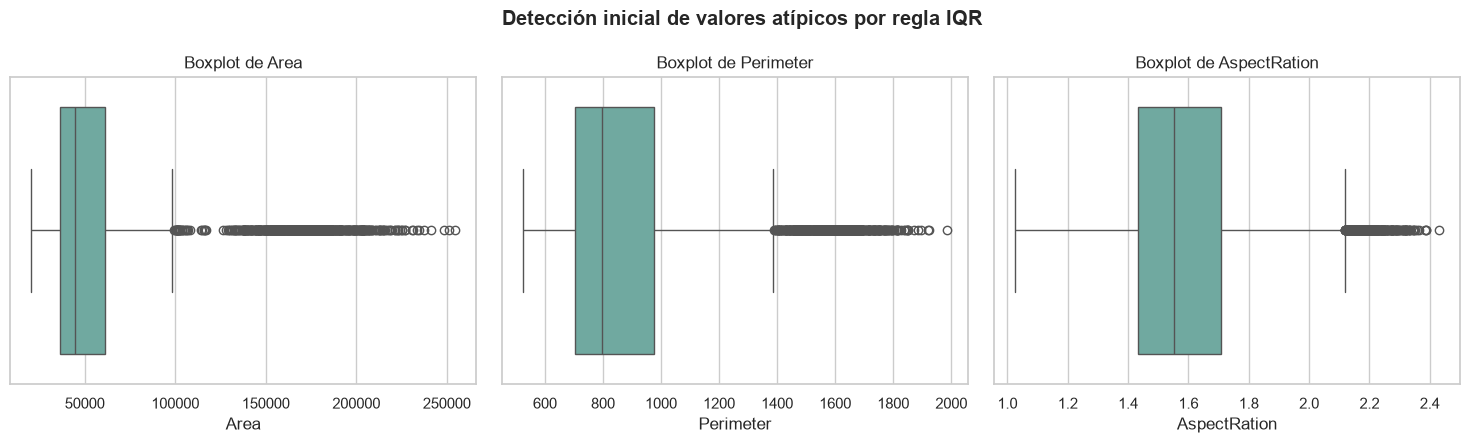

In [14]:
outlier_rows = []
for col in variables_clave:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < low) | (df[col] > high)).sum())
    outlier_rows.append([col, q1, q3, low, high, count, count / len(df) * 100])
outliers = pd.DataFrame(outlier_rows, columns=["Variable", "Q1", "Q3", "Límite inferior", "Límite superior", "Atípicos IQR", "%"])
display(outliers)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, variables_clave):
    sns.boxplot(data=df, x=col, ax=ax, color="#66b3a6")
    ax.set_title(f"Boxplot de {col}")
    ax.set_xlabel(col)
plt.suptitle("Detección inicial de valores atípicos por regla IQR", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** La regla IQR marca 551 casos en `Area`, 500 en `Perimeter` y 473 en `AspectRation`. No son automáticamente errores: el dataset reúne siete variedades con tamaños y formas diferentes, y las mediciones permanecen positivas y físicamente coherentes. Se conservarán; después se estudiarán por clase y con métodos robustos antes de decidir cualquier tratamiento.

## 8. Visualización inicial

### 8.1 Distribución de variedades

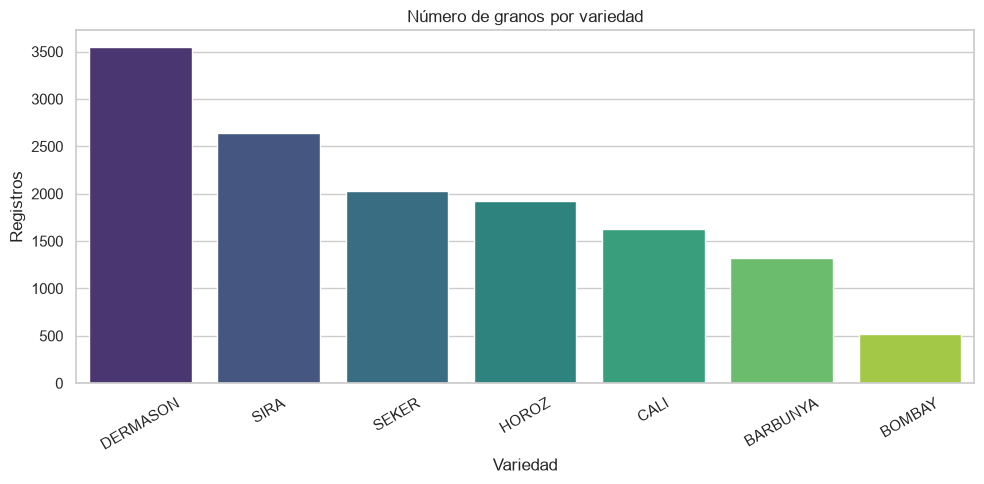

In [15]:
counts = df["Class"].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False)
plt.title("Número de granos por variedad")
plt.xlabel("Variedad")
plt.ylabel("Registros")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Interpretación.** `DERMASON` es la clase más frecuente (3,546) y `BOMBAY` la menos frecuente (522). El desbalance obliga a usar división estratificada y métricas por clase, como macro F1, en la clasificación posterior.

### 8.2 Histograma de área

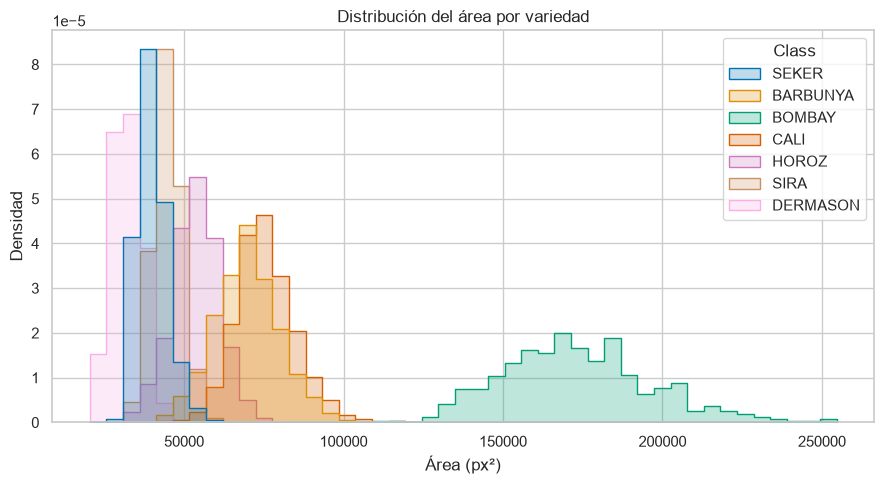

In [16]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Area", hue="Class", bins=45, element="step", stat="density", common_norm=False)
plt.title("Distribución del área por variedad")
plt.xlabel("Área (px²)")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()

**Interpretación.** Las variedades ocupan zonas distintas de tamaño: `BOMBAY` concentra áreas mayores, mientras `DERMASON`, `SEKER` y `SIRA` se ubican en rangos menores con solapamiento. `Area` es informativa, pero no basta por sí sola para separar todas las clases.

### 8.3 Relación entre ejes morfológicos

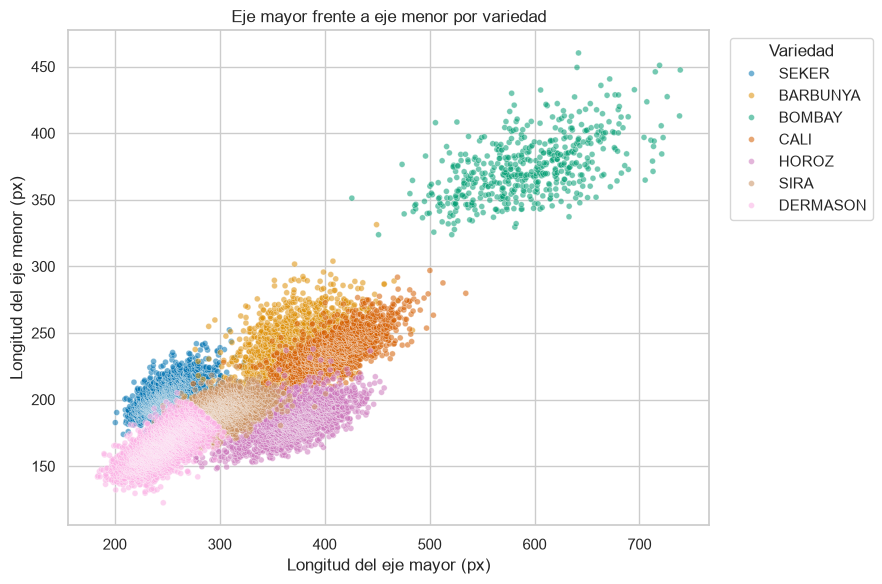

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="MajorAxisLength", y="MinorAxisLength", hue="Class", s=18, alpha=0.55)
plt.title("Eje mayor frente a eje menor por variedad")
plt.xlabel("Longitud del eje mayor (px)")
plt.ylabel("Longitud del eje menor (px)")
plt.legend(title="Variedad", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación.** Existe una relación positiva entre ambos ejes. Algunas variedades se separan por tamaño, pero otras se superponen; por ello el modelo deberá combinar ejes con proporciones y factores de forma.

### 8.4 Correlaciones entre mediciones

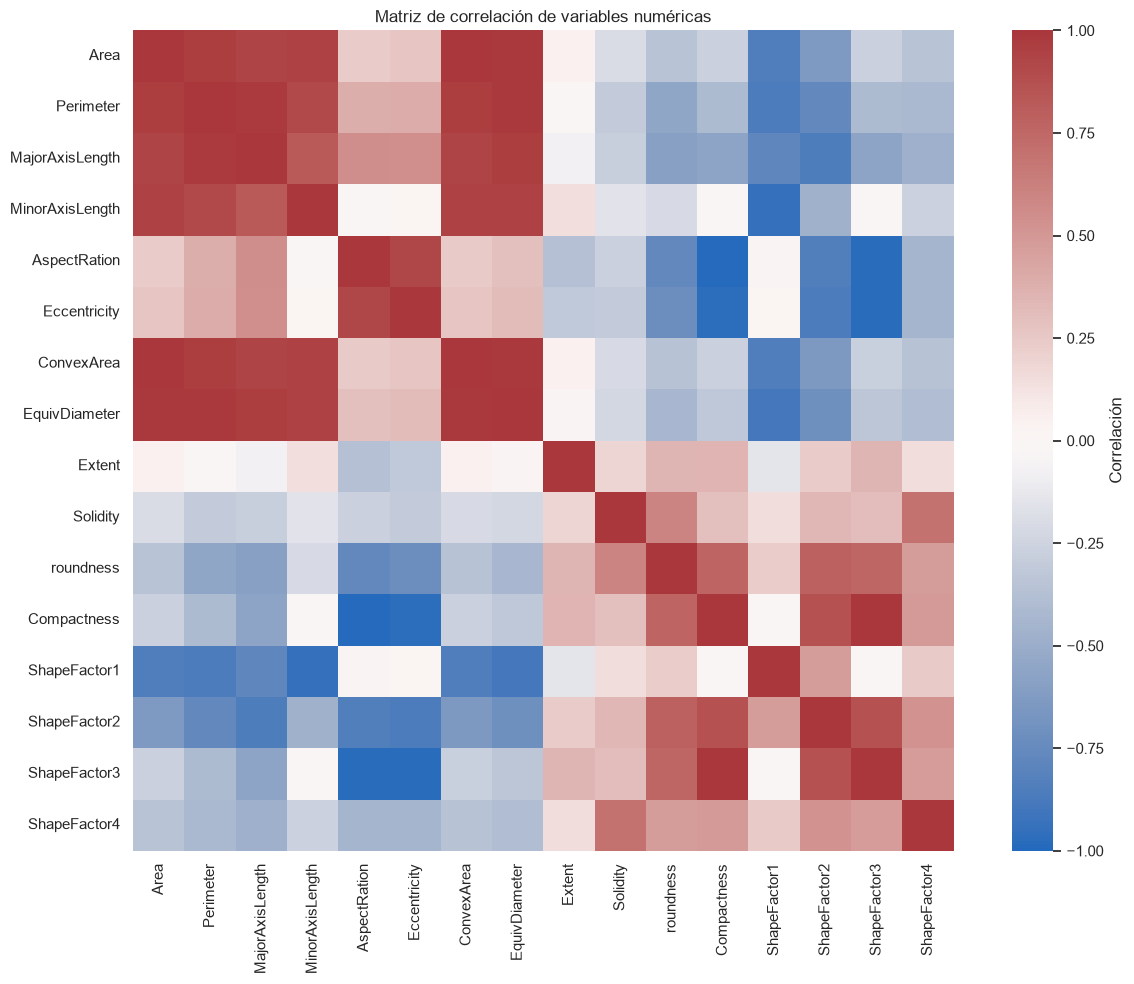

In [18]:
plt.figure(figsize=(13, 10))
sns.heatmap(numeric.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Correlación"})
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

**Interpretación.** `Area`, `ConvexArea` y `EquivDiameter` están fuertemente relacionadas porque describen o derivan del tamaño. Para predecir `Area` se excluirán `EquivDiameter` y, en el modelo principal, `ConvexArea`, evitando una predicción casi determinística y fuga de información.

## 9. Propuestas para análisis posteriores

### Regresión

- **Objetivo:** `Area`.
- **Propósito:** estimar el tamaño en píxeles a partir de contorno, ejes y forma.
- **Entradas candidatas:** `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, `AspectRation`, `Eccentricity`, `Extent`, `Solidity`, `roundness`, `Compactness` y factores de forma.
- **Control:** excluir `EquivDiameter` por derivarse directamente de `Area` y excluir/revisar `ConvexArea` por su dependencia geométrica.

### Clasificación

- **Objetivo:** `Class`.
- **Clases:** BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER y SIRA.
- **Entradas:** las 16 mediciones numéricas, con selección y evaluación para evitar redundancia.
- **Justificación:** responde directamente al objetivo de clasificación automática definido en Unidad I.

### Agrupamiento

- **Sin objetivo durante el ajuste.**
- **Variables candidatas:** `Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, `AspectRation`, `Eccentricity`, `Extent`, `Solidity`, `roundness`, `Compactness` y `ShapeFactor1` a `ShapeFactor4`.
- **Preparación futura:** deduplicación y estandarización, porque las escalas son diferentes.
- **Propósito:** comprobar si surgen perfiles naturales de tamaño y forma y después contrastarlos descriptivamente con `Class`.

## 10. Conclusión del diagnóstico

1. **Información:** 13,611 granos con 16 mediciones morfológicas y una etiqueta de siete variedades.
2. **Calidad general:** alta; estructura consistente, tipos correctos y completitud del 100%.
3. **Problemas:** 68 duplicados exactos, desbalance de clases, nombres `AspectRation`/`roundness` no normalizados y observaciones extremas que deben estudiarse.
4. **Variables que requieren tratamiento:** nombres de columnas, todas las numéricas antes de clustering por diferencia de escalas y variables derivadas al modelar `Area`.
5. **Faltantes:** no existen.
6. **Duplicados:** sí, 68 (0.500%), asociados a `HOROZ`.
7. **Atípicos:** la regla IQR detecta casos, pero son plausibles y no se eliminan en esta actividad.
8. **Transformaciones futuras:** deduplicar en una copia procesada, normalizar nombres, separar predictores/objetivos, estandarizar cuando corresponda y codificar `Class` para ciertos algoritmos.
9. **Aptitud:** los datos son adecuados para continuar, siempre que se controle duplicación, desbalance y fuga de información.
10. **Conocimiento esperado:** variables que distinguen variedades, clases que se confunden, capacidad de estimar tamaño y existencia de grupos morfológicos naturales.

## 11. Comprobación de integridad del archivo original

In [19]:
raw_hash_after = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"SHA-256 inicial: {raw_hash_before}")
print(f"SHA-256 final:   {raw_hash_after}")
print("Archivo original sin cambios:", raw_hash_before == raw_hash_after)
assert raw_hash_before == raw_hash_after

SHA-256 inicial: a9efa69741c6c5d95167c962a13da23a456f7e940402a5add12639790e01f714
SHA-256 final:   a9efa69741c6c5d95167c962a13da23a456f7e940402a5add12639790e01f714
Archivo original sin cambios: True


**Interpretación final.** La misma huella antes y después demuestra que el notebook solo leyó el dataset y que el archivo original permaneció intacto en `data/raw/`.

## Referencias

- UCI Machine Learning Repository. (2020). *Dry Bean* [Data set]. https://doi.org/10.24432/C50S4B
- Koklu, M., & Özkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, 105507. https://doi.org/10.1016/j.compag.2020.105507